**Outliers Analysis**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
file_path="C:\\Users\\user\\Downloads\\datasets\\Visadataset.csv"
visa_df=pd.read_csv(file_path)
visa_df.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


**box plot**

<img src="https://cdn.builtin.com/cdn-cgi/image/f=auto/sites/www.builtin.com/files/styles/ckeditor_optimize/public/inline-images/1_boxplots.jpg" jsaction class="sFlh5c FyHeAf iPVvYb" style="max-width: 512px; width: 400px; height: 300px; margin: 0px;" alt="What Is a Boxplot? (Definition + How to Use One) | Built In" jsname="kn3ccd">

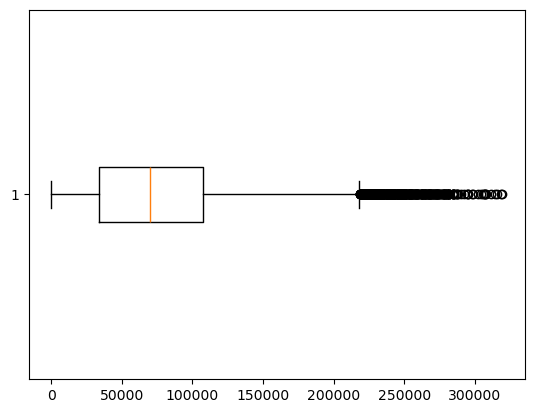

In [3]:
plt.boxplot(visa_df["prevailing_wage"],vert=False)
plt.show()
#black dots are outliers

**Dealing with Outliers**
- 1 removal of outliers
  
- 2 impute the outliers with median value
   - beacuse medain is not impacted by ouliers

- 3 cap the outliers with Q3,which are having more than Q3
- or cap the outliers with Q1,which are havig less tahn Q1

**Find the Outliers**

- Q3+1.5*IQR   - Q1-1.5*IQR

In [4]:
Q3=np.quantile(visa_df["prevailing_wage"],0.75)
Q1=np.quantile(visa_df["prevailing_wage"],0.25)
IQR=Q3-Q1
uper_bound=Q3+1.5*IQR
lower_bound=Q1-1.5*IQR

In [5]:
con1=visa_df["prevailing_wage"]>uper_bound
con2=visa_df["prevailing_wage"]<lower_bound
visa_df[con1|con2] #outliers data w.r.t to prevailing wage in Dataframe format
outliers=visa_df["prevailing_wage"][con1|con2] #specific column outliers data in series

In [6]:
outliers=visa_df["prevailing_wage"][con1|con2].values #into arrays
len(outliers)

427

In [7]:
def Outliers():
    Q3=np.quantile(visa_df["prevailing_wage"],0.75)
    Q1=np.quantile(visa_df["prevailing_wage"],0.25)
    IQR=Q3-Q1
    uper_bound=Q3+1.5*IQR
    lower_bound=Q1-1.5*IQR
    con1=visa_df["prevailing_wage"]>uper_bound
    con2=visa_df["prevailing_wage"]<lower_bound
    outliers=visa_df["prevailing_wage"][con1|con2] 
    outliers=visa_df["prevailing_wage"][con1|con2].values #into arrays
    return  len(outliers)

In [8]:
Outliers() #427 outliers

427

In [9]:
len(outliers)/len(visa_df)*100 #1.6% of total

1.6758241758241759

**Case 1: Removal of Outliers**
- we have 427ouliers in prevailing wage
- that means we have to remove 427 rows from entire dataframe

**non_outlier dataframe**

In [10]:
Q3=np.quantile(visa_df["prevailing_wage"],0.75)
Q1=np.quantile(visa_df["prevailing_wage"],0.25)
IQR=Q3-Q1
uper_bound=Q3+1.5*IQR
lower_bound=Q1-1.5*IQR
con1=visa_df["prevailing_wage"]<uper_bound
con2=visa_df["prevailing_wage"]>lower_bound
non_outliers=visa_df[["prevailing_wage"]][con1&con2]
non_outliers


,prevailing_wage
0,592.2029
1,83425.6500
2,122996.8600
3,83434.0300
4,149907.3900
...,...
25474,51104.7800
25475,77092.5700
25477,146298.8500
25478,86154.7700


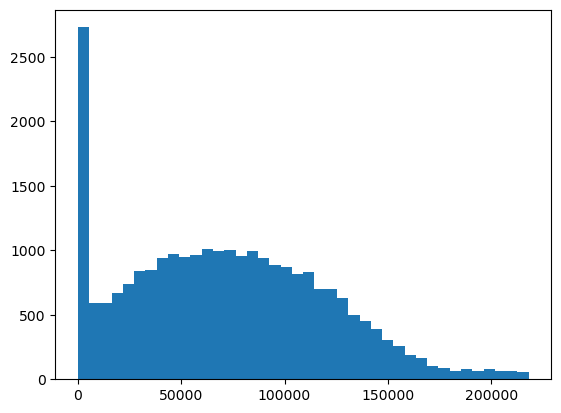

In [11]:
plt.hist(non_outliers,bins=40)
plt.show()

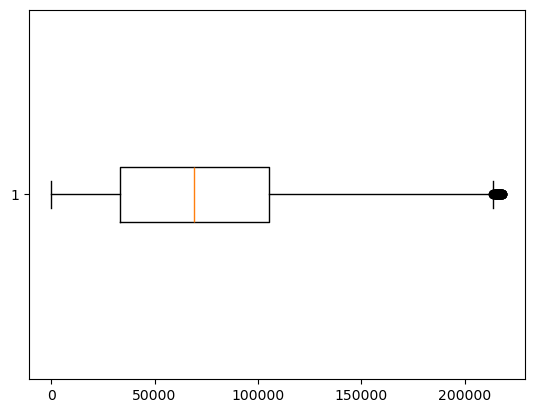

In [12]:
plt.boxplot(non_outliers,vert=False)
plt.show()

**case 2**
- **Impute with Median value**

- we got prevailing wage as 427 outliers

- we replace those 427 with median value of prevailing _wage

In [13]:
visa_df["prevailing_wage"].median()

70308.20999999999

In [14]:
outliers=visa_df[["prevailing_wage"]][con1|con2] 
outliers

,prevailing_wage
0,592.2029
1,83425.6500
2,122996.8600
3,83434.0300
4,149907.3900
...,...
25475,77092.5700
25476,279174.7900
25477,146298.8500
25478,86154.7700


In [15]:
len(outliers)

25480

In [16]:
uper_bound,lower_bound

(np.float64(218315.56125000003), np.float64(-76564.56875000002))

**all 427 outliers are replaced by median value**

In [17]:
l=[]
for i in visa_df["prevailing_wage"].values:
    if i>uper_bound or i<lower_bound:
        i=visa_df["prevailing_wage"].median()
        l.append(i)
    else:
        l.append(i)
print(l)
len(l)
    

[np.float64(592.2029), np.float64(83425.65), np.float64(122996.86), np.float64(83434.03), np.float64(149907.39), np.float64(78252.14), np.float64(53635.39), np.float64(418.2298), np.float64(74362.19), np.float64(67514.76), np.float64(83588.56), np.float64(70813.09), np.float64(28663.05), np.float64(107196.03), 70308.20999999999, np.float64(74108.02), np.float64(3706.79), np.float64(16132.61), np.float64(150441.13), np.float64(79948.12), np.float64(71128.98), np.float64(137694.98), np.float64(45642.39), np.float64(90108.38), np.float64(71286.04), np.float64(99489.65), np.float64(86332.95), np.float64(103029.33), np.float64(40925.86), np.float64(189190.48), np.float64(79594.12), np.float64(135866.13), np.float64(72077.57), np.float64(81921.18), 70308.20999999999, np.float64(92421.92), np.float64(2490.12), np.float64(110817.26), np.float64(50960.01), np.float64(125336.9), np.float64(39633.32), np.float64(156326.33), np.float64(43630.58), np.float64(54614.42), np.float64(28989.87), np.floa

25480

In [18]:
c=0
for i in l:
    if i==visa_df["prevailing_wage"].median():
        c=c+1
print(c)


427


In [19]:
pd.DataFrame(l,columns=["prevaialing_wage"])

,prevaialing_wage
0,592.2029
1,83425.6500
2,122996.8600
3,83434.0300
4,149907.3900
...,...
25475,77092.5700
25476,70308.2100
25477,146298.8500
25478,86154.7700


**Build in method for impute median in outliers removal process**
- np.where

In [20]:
dict1={"col1":[1,2,3,4],"col2":["A","B","C","D"]}
data=pd.DataFrame(dict1)
data

,col1,col2
0,1,A
1,2,B
2,3,C
3,4,D


**Here i want to impute 100 for the value>2**

- np.where() will takes 3 arguments
- conditon:data["col1"]>2
- if condition true then repalce the data["col1"] to 100
- if condition false then keep the same



In [21]:
np.where(data["col1"]>2 <true_value> <false_value>)

SyntaxError: invalid syntax (1931293442.py, line 1)

In [ ]:
con=data["col1"]>2
np.where(con,100,data["col1"])

**1) now either create new column and add this array**

In [ ]:
data["col3"]=np.where(con,100,data["col1"])
data

**2) repalce the existing columns**

In [ ]:
data["col1"]=np.where(con,100,data["col1"])
data

In [ ]:
data.drop(["col3"],axis=1)

In [ ]:
visa_df=pd.read_csv(file_path)

col1=visa_df["prevailing_wage"]>uper_bound
col2=visa_df["prevailing_wage"]<lower_bound
con=col1|col2
true_value=visa_df["prevailing_wage"].median()
visa_df["prevailing_wage"]=np.where(con,true_value,visa_df["prevailing_wage"])

In [ ]:
plt.boxplot(visa_df["prevailing_wage"])

In [ ]:

Q1,Q3

In [ ]:
visa_df[visa_df["prevailing_wage"]<Q1]

In [ ]:
l=[]
for i in visa_df["prevailing_wage"].values:
    if i>Q3:
        i=Q3
        l.append(i)
    else:
        l.append(i)
l

In [ ]:
non_outliers1=pd.DataFrame(l,columns=["prevailing_wage"])
non_outliers1

In [ ]:
plt.boxplot(non_outliers1,vert=False)

In [ ]:
6370